In [2]:
#Importing libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import ast
from datasets import load_dataset

#Loading the data
dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

#Cleaning the date and skills columns
df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else x)

c:\Users\amire\anaconda3\envs\python_course\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
# Defining countries that we will filter with
mena_countries = ['Sudan','Egypt', 'Kuwait', 'Saudi Arabia', 'Jordan', 'United Arab Emirates', 'Lebanon', 'Libya', 'Syria', 'Qatar', 'Iraq',
                   'Morocco', 'Palestine', 'Algeria', 'Tunisia', 'Bahrain', 'Oman', 'Yemen'  ]

# Job roles to compare, including senior variants, to see salary growth by seniority
job_roles = sorted(df['job_title_short'][df['job_title_short'].str.contains('Data')].unique().tolist())

# Filtering data frame and cleaning the salary column
df_mena = df[(df['job_country'].isin(mena_countries)) & (df['job_title_short'].isin(job_roles)) & (df['salary_year_avg'].dropna())]



In [57]:
job_order = df_mena.groupby('job_title_short')['salary_year_avg'].median().sort_values(ascending= False).index

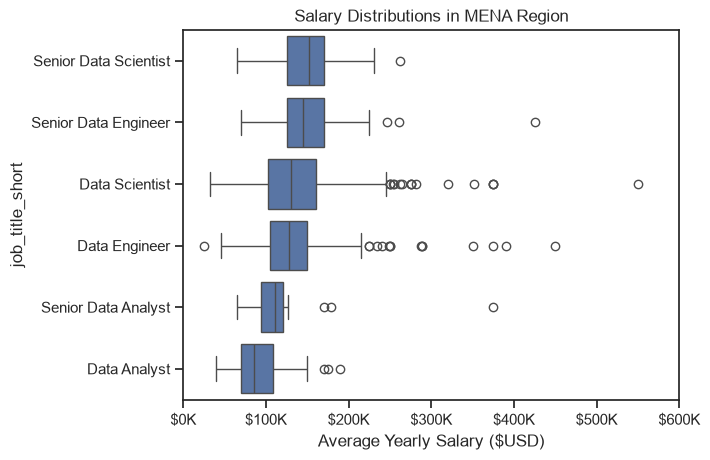

In [61]:
sns.boxplot(data = df_mena, x = 'salary_year_avg', y= 'job_title_short', order= job_order)
sns.set_theme(style= 'ticks')
plt.title('Salary Distributions in MENA Region')
plt.xlabel('Average Yearly Salary ($USD)')
ax = plt.gca()
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x,pos:f'${int(x/1000)}K'))
plt.xlim(0,600000)
plt.show()

In [5]:
# Now let's investigate top paying and most popular skills for data analysts
df_mena_DA = df[(df['job_country'].isin(mena_countries)) & (df['job_title_short']=='Data Analyst') & (df['job_skills'].notna())
                & (df['salary_year_avg'].notna())]

In [ ]:
df_mena_DA = df_mena_DA.explode('job_skills')

,salary_year_avg,job_skills
2390,70000.0,c
2390,70000.0,outlook
2390,70000.0,word
2390,70000.0,excel
2390,70000.0,powerpoint


In [55]:
top_paying_skills = df_mena_DA.groupby('job_skills')['salary_year_avg'].agg(['count', 'median']).sort_values(by= 'median', ascending= False).head(10)

In [ ]:
most_popular_skills = df_mena_DA.groupby('job_skills')['salary_year_avg'].agg(['count', 'median']).sort_values(by= 'count', ascending= False).head(10)

In [58]:
most_popular_skills = most_popular_skills.sort_values(by = 'median', ascending= False)

C:\Users\amire\AppData\Local\Temp\ipykernel_25836\685705851.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data = most_popular_skills, x ='median', y = 'job_skills', ax = ax[1],  palette = 'dark:b_r')
C:\Users\amire\AppData\Local\Temp\ipykernel_25836\685705851.py:14: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax[1].legend().set_visible(False)


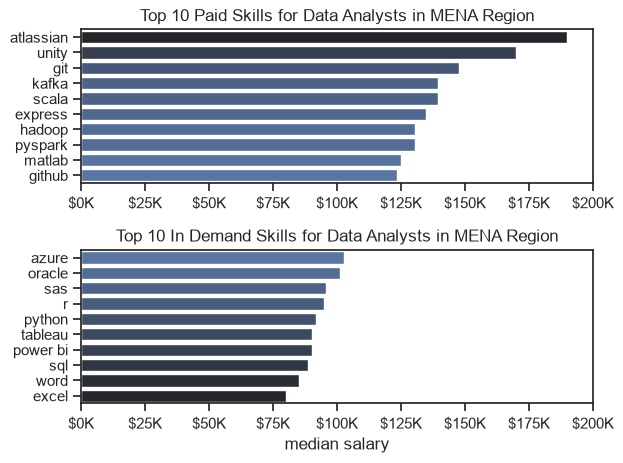

In [62]:
fig,ax = plt.subplots(2,1)
sns.set_theme(style = 'ticks')
sns.barplot(data = top_paying_skills, x ='median', y = 'job_skills', ax = ax[0], hue = 'median', palette = 'dark:b_r')

ax[0].legend().set_visible(False)
ax[0].set_title('Top 10 Paid Skills for Data Analysts in MENA Region')
ax[0].set_ylabel('')
ax[0].set_xlabel('')
ax[0].set_xlabel('')
ax[0].set_xlim(0,200000)
ax[0].xaxis.set_major_formatter(plt.FuncFormatter(lambda x,_ : f'${int(x/1000)}K'))

sns.barplot(data = most_popular_skills, x ='median', y = 'job_skills', ax = ax[1],  palette = 'dark:b_r')
ax[1].legend().set_visible(False)
ax[1].set_title('Top 10 In Demand Skills for Data Analysts in MENA Region')
ax[1].set_ylabel('')
ax[1].set_xlabel('median salary')
ax[1].set_xlim(0,200000)
ax[1].xaxis.set_major_formatter(plt.FuncFormatter(lambda x,_ : f'${int(x/1000)}K'))



fig.tight_layout()
plt.show()
